# Predicting Grain Boundary Segregation Energy (revised pipeline)

**Goal:** predict the characteristic grain boundary segregation energy **μ** (kJ/mol) of a solute in a
solvent metal from properties of the two elements alone, so alloys can be screened without atomistic simulation.

**Data:** Wagih, Larsen & Schuh, *Nature Communications* 11, 6376 (2020): segregation spectra for binary alloys,
each fitted with a skew-normal distribution (location μ, width σ, shape α). 427 rows covering 259 solvent–solute pairs;
some pairs appear more than once because they were simulated with different interatomic potentials.

**What changed from the original course project:**
1. **One consistent feature source.** Elemental properties for all 25 elements come from pymatgen's tabulated
   periodic-table data, instead of DFT values for 6 metals plus hand-entered values for the other 19.
2. **Physically meaningful descriptors.** Mismatch features are computed from raw values *before* scaling
   (the original computed ratios of z-scores), and the set adds atomic size misfit, the McLean elastic misfit energy,
   electronegativity difference and melting point ratio.
3. **No target leakage.** σ, α, the fit R² and Potential_ID come from the same simulations as μ, so they are excluded.
4. **Honest evaluation.** Grouped cross-validation keeps every alloy pair entirely in train or test, repeated 5 times;
   scaling is fit inside each training fold only.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import autograd.numpy as anp
from autograd import grad
from autograd.misc import flatten
from scipy.stats import spearmanr
from sklearn.model_selection import GroupKFold, KFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import RidgeCV
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error


warnings.filterwarnings("ignore")
SEED = 42
N_REPEATS = 5
N_FOLDS = 5
np.random.seed(SEED)

## Feature construction
Elemental properties come from pymatgen's tabulated periodic-table data; elastic constants are completed
and sanity-checked with isotropic-elasticity relations; mismatch descriptors are built from raw values.

In [2]:
import numpy as np
import pandas as pd
from pymatgen.core import Element

# 1 GPa * A^3 = 1e9 Pa * 1e-30 m^3 = 1e-21 J  ->  per mole: 1e-21 * 6.02214e23 J = 0.602214 kJ/mol
GPA_A3_TO_KJ_PER_MOL = 0.602214


def _num(x):
    """pymatgen returns floats, FloatWithUnit objects, or None; convert to float or NaN."""
    if x is None:
        return np.nan
    try:
        return float(x)
    except (TypeError, ValueError):
        return np.nan


ASSUMED_POISSON_RATIO = 0.3   # typical metal, used only when an element has no tabulated value
NU_TOLERANCE = 0.1            # max allowed gap between implied and tabulated Poisson's ratio


def _complete_elastic_constants(t, nu_tab):
    """Fill gaps and fix inconsistencies in bulk (K) and shear (G) moduli using isotropic elasticity.

    For an isotropic solid, K, G and Poisson's ratio v are linked:
        G = 3K(1 - 2v) / (2(1 + v))      K = 2G(1 + v) / (3(1 - 2v))
        implied v from K and G = (3K - 2G) / (2(3K + G))
    Rules, applied in order:
      1. K missing, G and v known      -> K from G and v
      2. G missing                     -> G from K and v (v = 0.3 if not tabulated)
      3. G inconsistent with K and v   -> G recomputed from K and v
    Every change is logged in t.attrs["elastic_fixes"].
    """
    fixes = []
    for el in t.index:
        K, G, nu = t.at[el, "bulk_modulus"], t.at[el, "shear_modulus"], nu_tab[el]
        if np.isnan(K) and not np.isnan(G) and not np.isnan(nu):
            t.at[el, "bulk_modulus"] = 2 * G * (1 + nu) / (3 * (1 - 2 * nu))
            fixes.append(f"{el}: bulk modulus missing, derived from G and v = {t.at[el, 'bulk_modulus']:.1f} GPa")
            continue
        v = nu if not np.isnan(nu) else ASSUMED_POISSON_RATIO
        G_from_K = 3 * K * (1 - 2 * v) / (2 * (1 + v))
        if np.isnan(G):
            t.at[el, "shear_modulus"] = G_from_K
            src = "tabulated v" if not np.isnan(nu) else f"assumed v = {ASSUMED_POISSON_RATIO}"
            fixes.append(f"{el}: shear modulus missing, derived from K ({src}) = {G_from_K:.1f} GPa")
        elif not np.isnan(nu):
            implied = (3 * K - 2 * G) / (2 * (3 * K + G))
            if abs(implied - nu) > NU_TOLERANCE:
                t.at[el, "shear_modulus"] = G_from_K
                fixes.append(f"{el}: tabulated G = {G:.0f} GPa implies v = {implied:.2f} vs tabulated {nu:.2f}; "
                             f"replaced with {G_from_K:.1f} GPa from K and v")
    t.attrs["elastic_fixes"] = fixes
    return t


def elemental_table(symbols):
    """Tabulated elemental properties for every symbol, from pymatgen's periodic-table data.

    Atomic (Slater) radius is used for size because it exists for all 25 elements, whereas
    metallic radius is missing for P, Si and Pb. Elastic constants are completed and
    sanity-checked by _complete_elastic_constants.
    """
    import warnings
    rows, nu_tab = [], {}
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        for s in symbols:
            e = Element(s)
            nu_tab[s] = _num(e.poissons_ratio)
            rows.append({
                "element": s,
                "atomic_mass": _num(e.atomic_mass),
                "atomic_radius": _num(e.atomic_radius),       # Angstrom
                "electronegativity": _num(e.X),               # Pauling
                "melting_point": _num(e.melting_point),       # K
                "bulk_modulus": _num(e.bulk_modulus),         # GPa
                "shear_modulus": _num(e.rigidity_modulus),    # GPa
                "density": _num(e.density_of_solid) / 1000,   # g/cm^3
                "molar_volume": _num(e.molar_volume),         # cm^3/mol
                "group": e.group,
                "period": e.row,
            })
    t = pd.DataFrame(rows).set_index("element")
    return _complete_elastic_constants(t, nu_tab)


def pair_features(df, elem):
    """df has Solvent and Solute columns; elem is the elemental table."""
    v = elem.loc[df["Solvent"]].reset_index(drop=True).add_prefix("solvent_")
    s = elem.loc[df["Solute"]].reset_index(drop=True).add_prefix("solute_")
    out = pd.concat([df.reset_index(drop=True), v, s], axis=1)

    r_v, r_s = out["solvent_atomic_radius"], out["solute_atomic_radius"]
    K_s, G_v = out["solute_bulk_modulus"], out["solvent_shear_modulus"]

    # Size misfit (signed and magnitude)
    out["size_misfit"] = (r_s - r_v) / r_v
    out["abs_size_misfit"] = out["size_misfit"].abs()

    # McLean / Friedel elastic strain energy of an oversized or undersized solute
    # E_el = 24*pi*K_s*G_v*r_s*r_v*(r_s - r_v)^2 / (3*K_s*r_s + 4*G_v*r_v)
    out["elastic_misfit_energy"] = (
        24 * np.pi * K_s * G_v * r_s * r_v * (r_s - r_v) ** 2
        / (3 * K_s * r_s + 4 * G_v * r_v)
    ) * GPA_A3_TO_KJ_PER_MOL

    # Chemical and cohesion differences
    out["electronegativity_diff"] = out["solute_electronegativity"] - out["solvent_electronegativity"]
    out["abs_electronegativity_diff"] = out["electronegativity_diff"].abs()
    out["melting_point_ratio"] = out["solute_melting_point"] / out["solvent_melting_point"]
    out["shear_modulus_ratio"] = out["solute_shear_modulus"] / out["solvent_shear_modulus"]
    out["bulk_modulus_ratio"] = out["solute_bulk_modulus"] / out["solvent_bulk_modulus"]
    out["molar_volume_ratio"] = out["solute_molar_volume"] / out["solvent_molar_volume"]
    out["density_ratio"] = out["solute_density"] / out["solvent_density"]
    out["group_diff"] = out["solute_group"] - out["solvent_group"]
    return out

## 1. Load data and build features

In [3]:
raw = pd.read_csv("../wagih_2020_data.csv")
raw["pair"] = raw["Solvent"] + "-" + raw["Solute"]
print(f"{len(raw)} rows, {raw['pair'].nunique()} unique solvent–solute pairs")

elements = sorted(set(raw["Solvent"]) | set(raw["Solute"]))
elem = elemental_table(elements)
print(f"Elemental table: {elem.shape[0]} elements, missing values: {int(elem.isna().sum().sum())}")
print("Elastic-constant checks and fixes:")
for f in elem.attrs["elastic_fixes"]:
    print("  -", f)
elem.round(3)

427 rows, 259 unique solvent–solute pairs
Elemental table: 25 elements, missing values: 0
Elastic-constant checks and fixes:
  - Mn: shear modulus missing, derived from K (assumed v = 0.3) = 55.4 GPa
  - Mo: tabulated G = 20 GPa implies v = 0.46 vs tabulated 0.31; replaced with 100.1 GPa from K and v
  - P: shear modulus missing, derived from K (assumed v = 0.3) = 5.1 GPa
  - Si: shear modulus missing, derived from K (assumed v = 0.3) = 46.2 GPa
  - Zr: bulk modulus missing, derived from G and v = 92.1 GPa


,atomic_mass,atomic_radius,electronegativity,melting_point,bulk_modulus,shear_modulus,density,molar_volume,group,period
element,,,,,,,,,,
Ag,107.868,1.60,1.93,1234.93,100.000,30.000,10.490,10.27,11,5
Al,26.982,1.25,1.61,933.47,76.000,26.000,2.700,10.00,13,3
Au,196.967,1.35,2.54,1337.33,220.000,27.000,19.300,10.21,11,6
Co,58.933,1.35,1.88,1768.00,180.000,75.000,8.900,6.67,9,4
Cr,51.996,1.40,1.66,2180.00,160.000,115.000,7.140,7.23,6,4
Cu,63.546,1.35,1.90,1357.77,140.000,48.000,8.920,7.11,11,4
Fe,55.845,1.40,1.83,1811.00,170.000,82.000,7.874,7.09,8,4
Mg,24.305,1.50,1.31,923.00,45.000,17.000,1.738,14.00,2,3
Mn,54.938,1.40,1.55,1519.00,120.000,55.385,7.470,7.35,7,4


In [4]:
data = pair_features(raw, elem)

LEAKY = ["Alpha", "Sigma", "R_Squared", "Potential_ID"]   # come from the same simulation as the target
META = ["Solvent", "Solute", "pair", "Mu"]
FEATURES = [c for c in data.columns if c not in LEAKY + META]
print(f"{len(FEATURES)} features:", FEATURES)
assert not data[FEATURES].isna().any().any(), "missing feature values"

X = data[FEATURES].to_numpy(float)
y = data["Mu"].to_numpy(float)
groups = data["pair"].to_numpy()
data["Mu"].describe().round(2)

31 features: ['solvent_atomic_mass', 'solvent_atomic_radius', 'solvent_electronegativity', 'solvent_melting_point', 'solvent_bulk_modulus', 'solvent_shear_modulus', 'solvent_density', 'solvent_molar_volume', 'solvent_group', 'solvent_period', 'solute_atomic_mass', 'solute_atomic_radius', 'solute_electronegativity', 'solute_melting_point', 'solute_bulk_modulus', 'solute_shear_modulus', 'solute_density', 'solute_molar_volume', 'solute_group', 'solute_period', 'size_misfit', 'abs_size_misfit', 'elastic_misfit_energy', 'electronegativity_diff', 'abs_electronegativity_diff', 'melting_point_ratio', 'shear_modulus_ratio', 'bulk_modulus_ratio', 'molar_volume_ratio', 'density_ratio', 'group_diff']


count    427.00
mean      -6.16
std       20.90
min     -129.00
25%       -7.00
50%       -2.00
75%        2.00
max       88.00
Name: Mu, dtype: float64

## 2. Models

* **Baseline:** always predict the training mean (R² ≈ 0 by construction). Every model must beat this.
* **Ridge regression** with built-in regularization search, standardized inside the fold.
* **Random forest** and **gradient boosting** (shallow trees, small learning rate to limit overfitting).
* **GIN (graph isomorphism network):** each alloy is a 2-node graph (solvent and solute nodes carrying their
  elemental properties plus a role flag). GIN layers update each node as MLP((1+ε)·h_self + h_neighbour);
  node embeddings are mean-pooled and combined with the pair descriptors in a regression head.
  Implemented from scratch with `autograd` (automatic differentiation for NumPy) and trained with Adam;
  early stopping uses a grouped validation split carved out of each training fold.

In [5]:
SOLVENT_COLS = [c for c in FEATURES if c.startswith("solvent_")]
SOLUTE_COLS = [c.replace("solvent_", "solute_") for c in SOLVENT_COLS]
PAIR_COLS = [c for c in FEATURES if c not in SOLVENT_COLS + SOLUTE_COLS]
IDX = {c: i for i, c in enumerate(FEATURES)}


def _init_dense(rng, d_in, d_out):
    return {"W": rng.normal(0, np.sqrt(2.0 / d_in), (d_in, d_out)), "b": np.zeros(d_out)}


def _dense(p, x):
    return anp.dot(x, p["W"]) + p["b"]


def init_gin(rng, d_node, d_pair, hidden=32, layers=3):
    dims = [d_node + 2] + [hidden] * layers          # +2 for the solvent/solute role flag
    convs = [{"eps": np.zeros(1), "l1": _init_dense(rng, a, b), "l2": _init_dense(rng, b, b)}
             for a, b in zip(dims[:-1], dims[1:])]
    head = {"l1": _init_dense(rng, hidden + d_pair, hidden), "l2": _init_dense(rng, hidden, 1)}
    return {"convs": convs, "head": head}


def gin_forward(params, nodes, pair):
    """nodes: (batch, 2, d) with node 0 = solvent, node 1 = solute; pair: (batch, d_pair).

    GIN update for every node v:  h_v' = MLP((1 + eps) * h_v + sum over neighbours h_u).
    In a 2-node graph each node's only neighbour is the other node, i.e. h[:, ::-1].
    """
    h = nodes
    for c in params["convs"]:
        agg = (1 + c["eps"]) * h + h[:, ::-1, :]
        h = anp.maximum(0, _dense(c["l2"], anp.maximum(0, _dense(c["l1"], agg))))
    g = anp.mean(h, axis=1)                                    # global mean pooling
    z = anp.concatenate([g, pair], axis=1)
    hd = params["head"]
    return _dense(hd["l2"], anp.maximum(0, _dense(hd["l1"], z)))[:, 0]


def huber(r, delta=1.0):
    a = anp.abs(r)
    return anp.mean(anp.where(a <= delta, 0.5 * r ** 2, delta * (a - 0.5 * delta)))


class GINModel:
    """Graph isomorphism network on 2-node alloy graphs, trained with Adam.

    Scalers are fit on the training fold only; early stopping uses a grouped validation split
    (15% of the training alloy pairs) so validation alloys are never seen during training.
    """
    def __init__(self, seed=SEED, max_iters=2000, patience=150, lr=3e-3, weight_decay=1e-3):
        self.seed, self.max_iters, self.patience = seed, max_iters, patience
        self.lr, self.weight_decay = lr, weight_decay

    def _arrays(self, Xm):
        sv = self.node_scaler.transform(Xm[:, [IDX[c] for c in SOLVENT_COLS]])
        su = self.node_scaler.transform(Xm[:, [IDX[c] for c in SOLUTE_COLS]])
        n = len(Xm)
        nodes = np.stack([np.hstack([sv, np.tile([1.0, 0.0], (n, 1))]),
                          np.hstack([su, np.tile([0.0, 1.0], (n, 1))])], axis=1)
        pair = self.pair_scaler.transform(Xm[:, [IDX[c] for c in PAIR_COLS]])
        return nodes, pair

    def fit(self, Xm, ym, gm):
        rng = np.random.default_rng(self.seed)
        ug = np.unique(gm)
        val_groups = set(rng.choice(ug, size=max(1, int(0.15 * len(ug))), replace=False))
        val = np.array([g in val_groups for g in gm])

        # one scaler shared by solvent and solute nodes, so an element maps to the same vector in either role
        node_block = np.vstack([Xm[~val][:, [IDX[c] for c in SOLVENT_COLS]],
                                Xm[~val][:, [IDX[c] for c in SOLUTE_COLS]]])
        self.node_scaler = StandardScaler().fit(node_block)
        self.pair_scaler = StandardScaler().fit(Xm[~val][:, [IDX[c] for c in PAIR_COLS]])
        self.y_mu, self.y_sd = ym[~val].mean(), ym[~val].std()

        nodes, pair = self._arrays(Xm)
        yt = (ym - self.y_mu) / self.y_sd
        n_tr, p_tr, y_tr = nodes[~val], pair[~val], yt[~val]
        n_va, p_va, y_va = nodes[val], pair[val], yt[val]

        params = init_gin(rng, len(SOLVENT_COLS), len(PAIR_COLS))
        flat, unflatten = flatten(params)

        def objective(w):
            p = unflatten(w)
            return huber(gin_forward(p, n_tr, p_tr) - y_tr) + self.weight_decay * anp.sum(w ** 2)

        g_fn = grad(objective)
        m, v = np.zeros_like(flat), np.zeros_like(flat)
        b1, b2, eps = 0.9, 0.999, 1e-8
        best, best_w, wait = np.inf, flat.copy(), 0
        for t in range(1, self.max_iters + 1):                  # full-batch Adam
            gr = g_fn(flat)
            m = b1 * m + (1 - b1) * gr
            v = b2 * v + (1 - b2) * gr ** 2
            flat = flat - self.lr * (m / (1 - b1 ** t)) / (np.sqrt(v / (1 - b2 ** t)) + eps)
            val_loss = huber(gin_forward(unflatten(flat), n_va, p_va) - y_va)
            if val_loss < best - 1e-6:
                best, best_w, wait = val_loss, flat.copy(), 0
            else:
                wait += 1
                if wait >= self.patience:
                    break
        self.params = unflatten(best_w)
        self.n_iters_ = t
        return self

    def predict(self, Xm):
        nodes, pair = self._arrays(Xm)
        return np.asarray(gin_forward(self.params, nodes, pair)) * self.y_sd + self.y_mu


MODELS = {
    "Baseline (mean)": lambda: DummyRegressor(),
    "Ridge regression": lambda: make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-3, 3, 25))),
    "Random forest": lambda: RandomForestRegressor(n_estimators=500, min_samples_leaf=3, max_features=0.5,
                                                   random_state=SEED, n_jobs=-1),
    "Gradient boosting": lambda: GradientBoostingRegressor(n_estimators=300, learning_rate=0.03, max_depth=2,
                                                           subsample=0.8, random_state=SEED),
    "GIN (graph neural network)": lambda: GINModel(),
}

## 3. Grouped cross-validation

For each of 5 repeats, the 259 alloy pairs are shuffled into 5 folds. Every row is predicted exactly once per repeat
by a model that never saw that alloy pair. Metrics are computed on the pooled out-of-fold predictions of each repeat,
then averaged (± standard deviation across repeats).

In [6]:
def cross_validate(make_model, Xm, ym, gm, splitter="group", repeats=N_REPEATS):
    scores, oof_all = [], []
    for r in range(repeats):
        if splitter == "group":
            cv = GroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED + r).split(Xm, ym, gm)
        else:
            cv = KFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED + r).split(Xm, ym)
        oof = np.zeros_like(ym)
        for tr, te in cv:
            m = make_model()
            if isinstance(m, GINModel):
                m.fit(Xm[tr], ym[tr], gm[tr])
            else:
                m.fit(Xm[tr], ym[tr])
            oof[te] = m.predict(Xm[te])
        oof_all.append(oof)
        scores.append({
            "R2": r2_score(ym, oof),
            "RMSE": np.sqrt(mean_squared_error(ym, oof)),
            "MAE": mean_absolute_error(ym, oof),
            "Spearman": spearmanr(ym, oof).correlation,
        })
    s = pd.DataFrame(scores)
    return s.mean(), s.std(), np.mean(oof_all, axis=0)


results, oof_preds = {}, {}
for name, make_model in MODELS.items():
    mean, std, oof = cross_validate(make_model, X, y, groups)
    results[name] = {f"{k}": mean[k] for k in mean.index} | {f"{k}_sd": std[k] for k in std.index}
    oof_preds[name] = oof
    print(f"{name:28s} R2 = {mean['R2']:.3f} ± {std['R2']:.3f} | RMSE = {mean['RMSE']:.2f} | "
          f"MAE = {mean['MAE']:.2f} | Spearman = {mean['Spearman']:.3f}")

res = pd.DataFrame(results).T
res[["R2", "R2_sd", "RMSE", "RMSE_sd", "MAE", "Spearman"]].round(3)

Baseline (mean)              R2 = -0.007 ± 0.007 | RMSE = 20.95 | MAE = 11.95 | Spearman = -0.063
Ridge regression             R2 = 0.178 ± 0.012 | RMSE = 18.93 | MAE = 11.12 | Spearman = 0.240


Random forest                R2 = 0.242 ± 0.019 | RMSE = 18.17 | MAE = 10.03 | Spearman = 0.386


Gradient boosting            R2 = 0.177 ± 0.031 | RMSE = 18.93 | MAE = 10.74 | Spearman = 0.340


GIN (graph neural network)   R2 = 0.152 ± 0.042 | RMSE = 19.22 | MAE = 11.40 | Spearman = 0.273


,R2,R2_sd,RMSE,RMSE_sd,MAE,Spearman
Baseline (mean),-0.007,0.007,20.947,0.075,11.947,-0.063
Ridge regression,0.178,0.012,18.927,0.135,11.125,0.240
Random forest,0.242,0.019,18.173,0.227,10.030,0.386
Gradient boosting,0.177,0.031,18.933,0.355,10.738,0.340
GIN (graph neural network),0.152,0.042,19.220,0.474,11.403,0.273


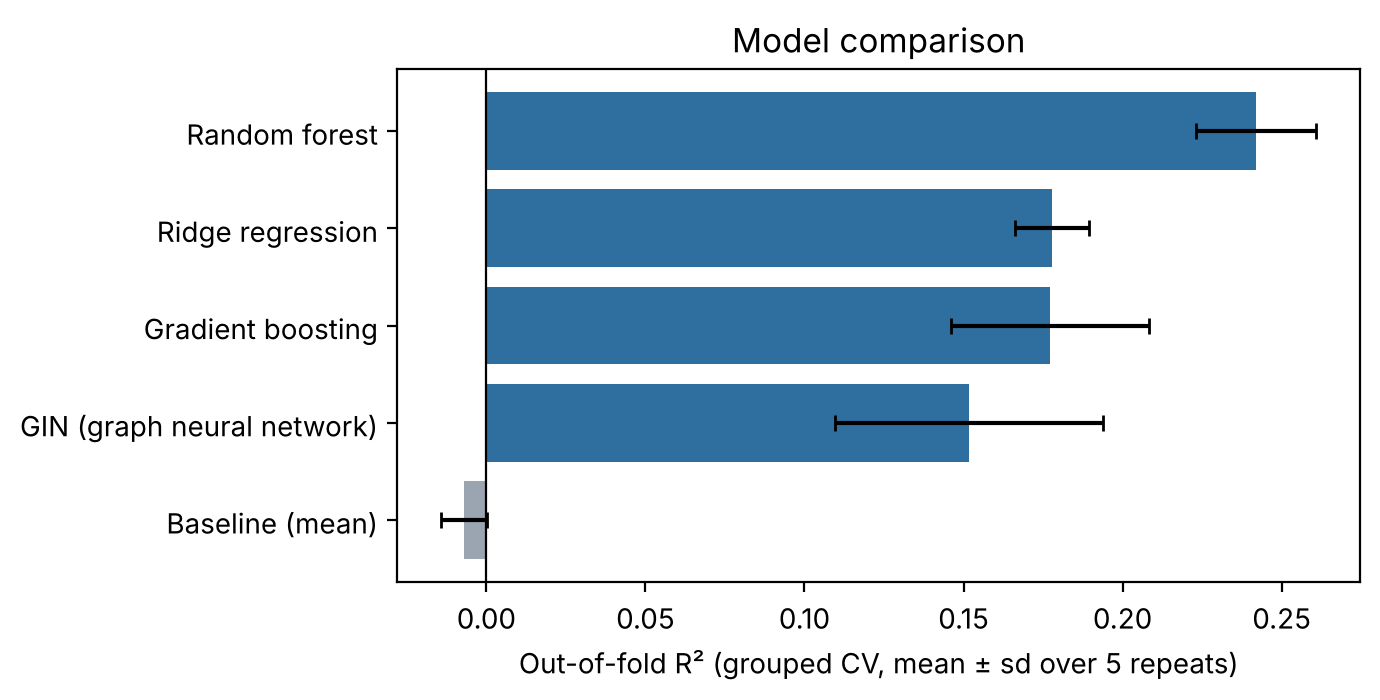

In [7]:
order = res.sort_values("R2").index
fig, ax = plt.subplots(figsize=(7, 3.6))
colors = ["#9aa5b1" if n.startswith("Baseline") else "#2f6f9f" for n in order]
ax.barh(order, res.loc[order, "R2"], xerr=res.loc[order, "R2_sd"], color=colors, capsize=3)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Out-of-fold R² (grouped CV, mean ± sd over 5 repeats)")
ax.set_title("Model comparison")
plt.tight_layout()
plt.savefig("fig_model_comparison.png", dpi=160)
plt.show()

## 4. How much of μ can elemental features explain at all?

243 of the 427 rows belong to alloy pairs simulated with more than one interatomic potential. Those rows have
*identical* elemental features but different μ, so no model built on elemental features can tell them apart.
The best any such model can do is predict each pair's average μ, which sets a ceiling on R².

In [8]:
pair_mean = data.groupby("pair")["Mu"].transform("mean")
r2_ceiling = r2_score(y, pair_mean)
print(f"R² ceiling for any elemental-feature model: {r2_ceiling:.3f}")
for name in res.index.drop("Baseline (mean)"):
    print(f"  {name:28s} reaches {res.loc[name, 'R2'] / r2_ceiling:5.1%} of the achievable R²")

# The same models on the pair-averaged target (259 unique alloys, potential-to-potential noise averaged out)
agg = raw.groupby(["Solvent", "Solute"], as_index=False)["Mu"].mean()
agg["pair"] = agg["Solvent"] + "-" + agg["Solute"]
data_avg = pair_features(agg, elem)
Xa, ya, ga = data_avg[FEATURES].to_numpy(float), data_avg["Mu"].to_numpy(float), data_avg["pair"].to_numpy()
avg_rows = {}
for name in ["Ridge regression", "Random forest", "Gradient boosting"]:
    m, s_, _ = cross_validate(MODELS[name], Xa, ya, ga)
    avg_rows[name] = {"R2": m["R2"], "R2_sd": s_["R2"], "RMSE": m["RMSE"], "Spearman": m["Spearman"]}
avg_df = pd.DataFrame(avg_rows).T
avg_df.round(3)

R² ceiling for any elemental-feature model: 0.715
  Ridge regression             reaches 24.9% of the achievable R²
  Random forest                reaches 33.9% of the achievable R²
  Gradient boosting            reaches 24.8% of the achievable R²
  GIN (graph neural network)   reaches 21.2% of the achievable R²


,R2,R2_sd,RMSE,Spearman
Ridge regression,0.271,0.023,17.477,0.254
Random forest,0.331,0.031,16.736,0.417
Gradient boosting,0.262,0.025,17.580,0.395


## 5. Checking the evaluation choices

Two design choices could change the scores, so the best model is re-run each way:
* **Random vs grouped splits.** A random split can put the same alloy pair (simulated with a different potential)
  in both training and test data.
* **Including σ and α.** They are fitted from the same segregation spectrum as μ, so they would not exist for a new alloy.

In [9]:
best_name = res.drop("Baseline (mean)").sort_values("R2", ascending=False).index[0]
make_best = MODELS[best_name]
print("Best model:", best_name)

X_leaky = data[FEATURES + ["Sigma", "Alpha"]].to_numpy(float)
checks = {
    "Grouped CV, no leakage (honest)": cross_validate(make_best, X, y, groups, "group")[0],
    "Random CV, no leakage": cross_validate(make_best, X, y, groups, "random")[0],
    "Grouped CV, with Sigma and Alpha": cross_validate(make_best, X_leaky, y, groups, "group")[0],
}
check_df = pd.DataFrame(checks).T[["R2", "RMSE", "Spearman"]]
check_df.round(3)

Best model: Random forest


,R2,RMSE,Spearman
"Grouped CV, no leakage (honest)",0.242,18.173,0.386
"Random CV, no leakage",0.176,18.944,0.345
"Grouped CV, with Sigma and Alpha",0.249,18.093,0.484


**What this shows** (numbers from the run above):
* **Random splits scored lower, not higher** (R² 0.18 vs 0.24). Repeated alloy pairs have identical features but
  different μ, so a model that memorises one potential's value is penalised on the other. Grouped CV remains the right
  design because it is the only one that measures performance on alloys the model has never seen.
* **σ and α barely change R²** (0.25 vs 0.24) but raise rank correlation (0.48 vs 0.39). They carry some information
  about μ, but because they come from the same simulation they cannot be used to screen new alloys, so they stay out.

## 6. Diagnostics for the best model

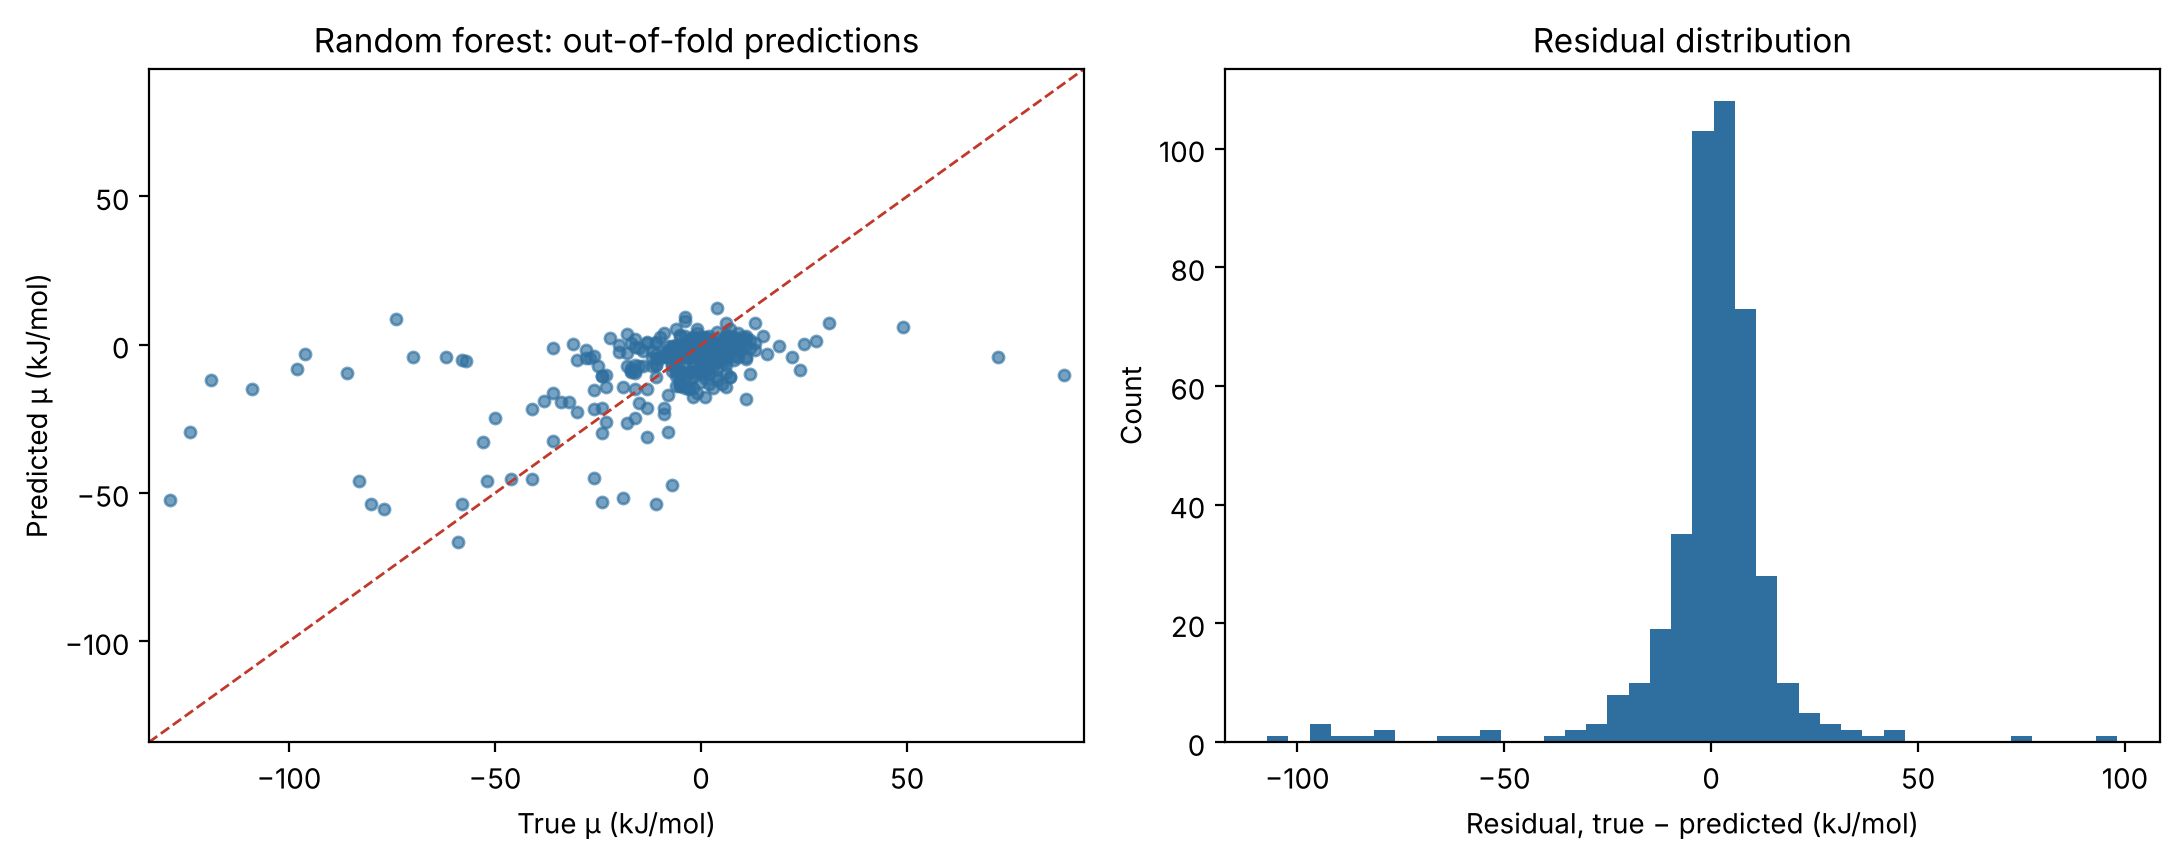

MAE on the 90% of alloys with |μ| ≤ 26 kJ/mol: 6.69; on the extreme 10%: 40.58


In [10]:
pred = oof_preds[best_name]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
lim = [min(y.min(), pred.min()) - 5, max(y.max(), pred.max()) + 5]
axes[0].scatter(y, pred, s=16, alpha=0.65, color="#2f6f9f")
axes[0].plot(lim, lim, "--", color="#c0392b", lw=1)
axes[0].set(xlim=lim, ylim=lim, xlabel="True μ (kJ/mol)", ylabel="Predicted μ (kJ/mol)",
            title=f"{best_name}: out-of-fold predictions")
resid = y - pred
axes[1].hist(resid, bins=40, color="#2f6f9f")
axes[1].set(xlabel="Residual, true − predicted (kJ/mol)", ylabel="Count", title="Residual distribution")
plt.tight_layout()
plt.savefig("fig_parity_residuals.png", dpi=160)
plt.show()

core = np.abs(y) <= np.percentile(np.abs(y), 90)
print(f"MAE on the 90% of alloys with |μ| ≤ {np.percentile(np.abs(y), 90):.0f} kJ/mol: "
      f"{mean_absolute_error(y[core], pred[core]):.2f}; on the extreme 10%: {mean_absolute_error(y[~core], pred[~core]):.2f}")

### Feature importance
Permutation importance measured on held-out folds (how much the error grows when one feature is shuffled),
using the random forest because it is fast to refit.

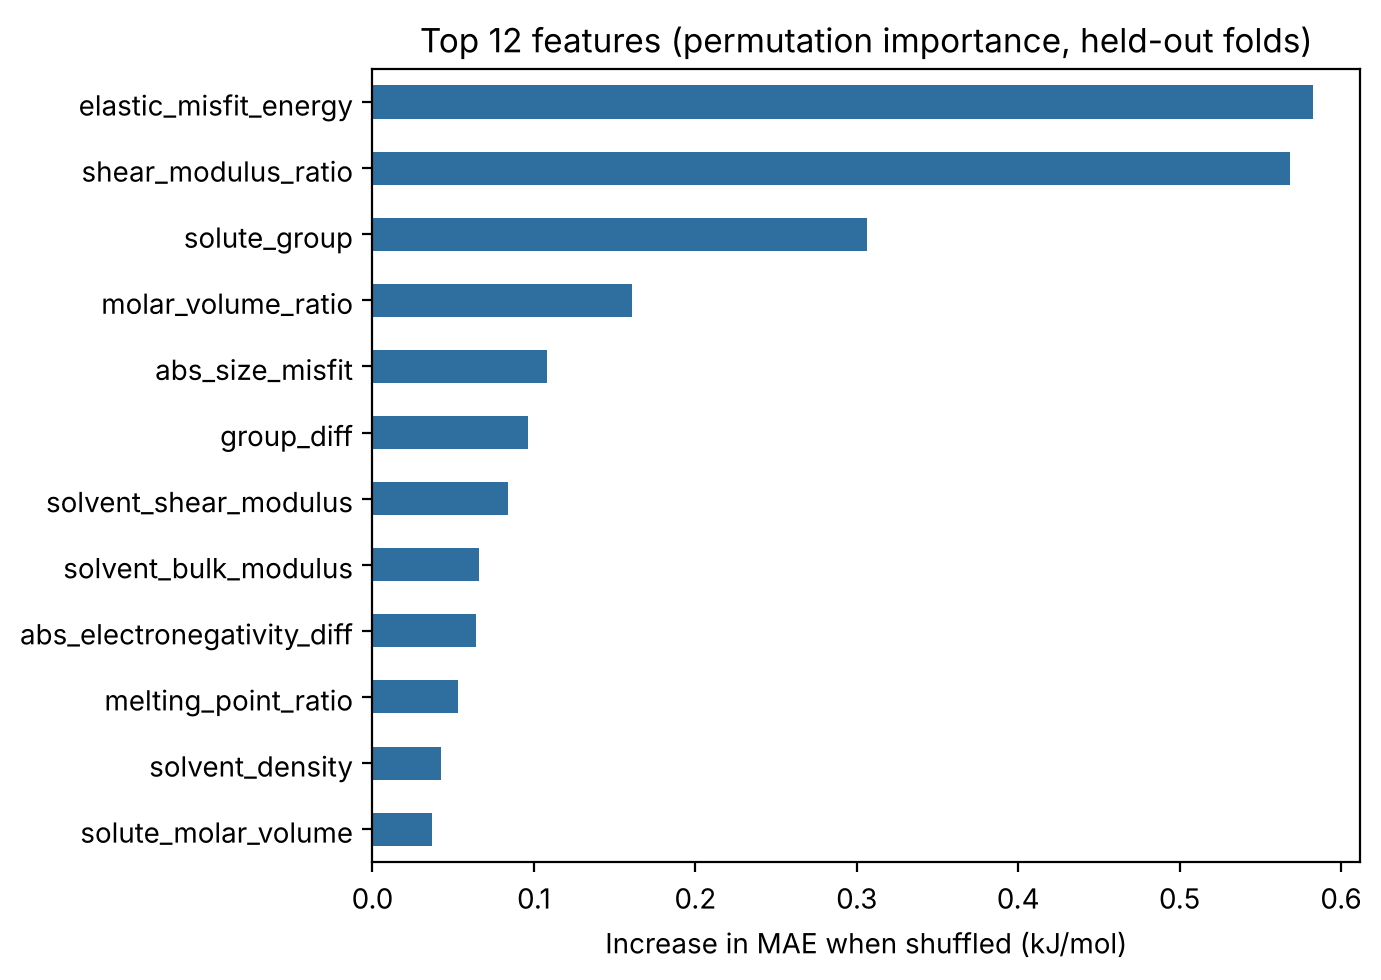

elastic_misfit_energy         0.583
shear_modulus_ratio           0.568
solute_group                  0.306
molar_volume_ratio            0.161
abs_size_misfit               0.108
group_diff                    0.096
solvent_shear_modulus         0.084
solvent_bulk_modulus          0.066
abs_electronegativity_diff    0.064
melting_point_ratio           0.053
solvent_density               0.042
solute_molar_volume           0.037
dtype: float64

In [11]:
imp = np.zeros(len(FEATURES))
for tr, te in GroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED).split(X, y, groups):
    rf = MODELS["Random forest"]().fit(X[tr], y[tr])
    pi = permutation_importance(rf, X[te], y[te], n_repeats=20, random_state=SEED,
                                scoring="neg_mean_absolute_error", n_jobs=-1)
    imp += pi.importances_mean / N_FOLDS
imp = pd.Series(imp, index=FEATURES).sort_values()

fig, ax = plt.subplots(figsize=(7, 5))
imp.tail(12).plot.barh(ax=ax, color="#2f6f9f")
ax.set_xlabel("Increase in MAE when shuffled (kJ/mol)")
ax.set_title("Top 12 features (permutation importance, held-out folds)")
plt.tight_layout()
plt.savefig("fig_feature_importance.png", dpi=160)
plt.show()
imp.sort_values(ascending=False).head(12).round(3)

## 7. Conclusions

(Numbers from the run above; the cell below saves them to CSV.)

1. **Random forest is the best model:** out-of-fold R² 0.24 ± 0.02 under grouped 5-fold CV repeated 5 times
   (RMSE 18.2, MAE 10.0 kJ/mol, Spearman 0.39), against a mean-prediction baseline with MAE 11.9 kJ/mol.
2. **The data caps what is achievable.** Because repeated pairs differ only by interatomic potential, no
   elemental-feature model can exceed R² 0.715; the random forest reaches about a third of that. On the
   pair-averaged target (259 unique alloys) it reaches R² 0.33.
3. **Errors are concentrated in the extremes.** MAE is 6.7 kJ/mol for the 90% of alloys with |μ| ≤ 26 kJ/mol but
   40.6 kJ/mol for the most extreme 10%, which the model systematically underpredicts.
4. **The physics shows up in the features.** The McLean elastic misfit energy, the solute–solvent shear modulus ratio
   and the solute's periodic-table group are the most important predictors, consistent with elastic theory of segregation.
5. **The GIN did not beat tree ensembles** (R² 0.15). On a 2-node graph, a GNN amounts to a symmetric neural network
   over element pairs; a graph approach would need atomic-scale grain boundary structures to add real information.

**Next steps:** add chemical descriptors (cohesive energy, surface energy, d-band filling), model the potential as a
known simulation input, predict σ and α jointly with μ, and use atomic-environment graphs of grain boundary sites.

In [12]:
summary = res[["R2", "R2_sd", "RMSE", "MAE", "Spearman"]].round(3)
summary.to_csv("model_results.csv")
avg_df.round(3).to_csv("model_results_pair_averaged.csv")
print(f"R² ceiling: {r2_ceiling:.3f}")
check_df.round(3).to_csv("evaluation_checks.csv")
imp.sort_values(ascending=False).round(4).to_csv("feature_importance.csv")
print(summary.to_string())
print()
print(check_df.round(3).to_string())

R² ceiling: 0.715
                               R2  R2_sd    RMSE     MAE  Spearman
Baseline (mean)            -0.007  0.007  20.947  11.947    -0.063
Ridge regression            0.178  0.012  18.927  11.125     0.240
Random forest               0.242  0.019  18.173  10.030     0.386
Gradient boosting           0.177  0.031  18.933  10.738     0.340
GIN (graph neural network)  0.152  0.042  19.220  11.403     0.273

                                     R2    RMSE  Spearman
Grouped CV, no leakage (honest)   0.242  18.173     0.386
Random CV, no leakage             0.176  18.944     0.345
Grouped CV, with Sigma and Alpha  0.249  18.093     0.484
